# E127: is the least-squares start's poor faithfulness in its weights or in where they sit?

**The answer.** It is in where they sit. Splitting a fine-tune onto the alive subcomponents by least squares made the decomposition easier to break than leaving the update in Δ. The start's own weight change, kept in Δ, reads better than do-nothing on both tasks; moved onto the subcomponents, it reads nearly three times worse on lowercase. Only the adversary finds this. Holding the alive subcomponents fully on removes the excess, but it also flattens a state whose change sits in Δ, so that last reading is not yet specific.


## What we were trying to test

Each matrix of the released decomposition is $W = UV^\top + \Delta$: the alive subcomponents' write and read vectors in $U, V$, the rest in $\Delta$. A fine-tune changes the weights by $\delta W$. Earlier runs found that the least-squares start, the decomposition with $\delta W$ placed on the alive subcomponents by the least-squares split, reads worse under E34's adversarial check than do-nothing, where $\delta W$ sits in $\Delta$. Two things differ between them, and this run pulls them apart with a third state:

- **do-nothing**: target $W_0 + \delta W$, the update in $\Delta$.
- **least-squares start**: the alive subcomponents move to $(U + dU, V + dV)$. Its weight change is $S = (U + dU)(V + dV)^\top - UV^\top$, which drops the split's remainder, so $S \neq \delta W$.
- **same function in Δ**: target $W_0 + S$, subcomponents untouched. It computes what the start computes, with its change where do-nothing keeps its own.

The check is an adversary of 20 sign steps that sets every mask to maximise the KL divergence from the target, on 256 Pile rows. The ratio is that KL over W₀'s: 1 means the update made the decomposition no easier to break. The noise floor is 0.209, W₀'s spread over three adversary seeds.

The start's excess over do-nothing splits exactly into a **function part**, the same function in Δ minus do-nothing, and a **placement part**, the start minus the same function in Δ. Three reads then ask what carries the placement part. The **hold** fixes every alive subcomponent's mask at 1, so the adversary can move only the dead subcomponents and Δ; W₀ held against W₀ free checks that the hold changes anything. **Random masks** read the same states with no adversary. **Coherence**, $\kappa = \|\sum_c D_c\|^2 / \sum_c \|D_c\|^2$ over the per-subcomponent changes $D_c$, says whether those changes cancel: below 1 they do, and a sign-flip null reads about 1.

Two fine-tunes: lowercase, whose excess was 3.5 ratio points, and emoticon, whose excess was 0.18.


## What we expected, and why

The split keeps most of $\delta W$, so its own change should damage Pile text about as much: the lean was that the excess is placement on lowercase, and that emoticon's small excess reads within the floor. If it was placement, the hold was expected to remove it, and W₀ held was expected at 0.5 to 1.2 nats, from E20's earlier reading with the alive subcomponents kept whole. Random masks were expected not to see it, as E15 found for an earlier split state. Whether the changes cancel more on the failing states was a coin toss.


## Is the excess in the start's weights or in where they sit?


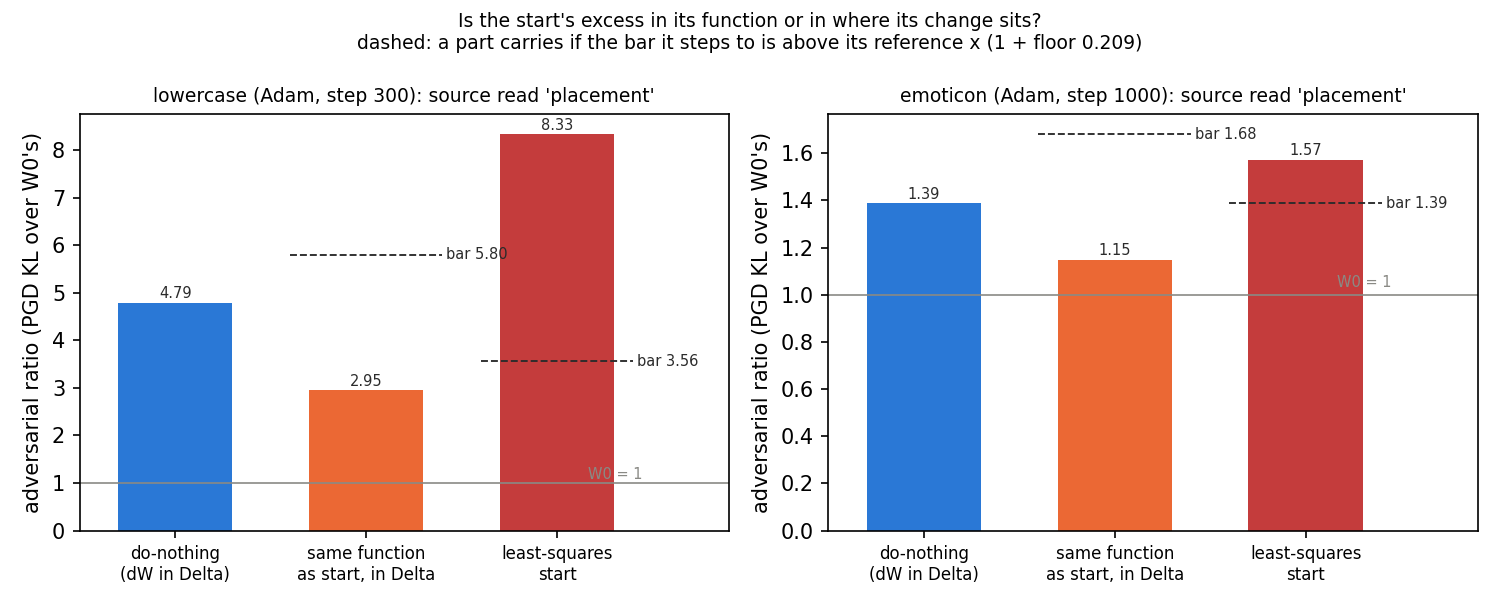

In [ ]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/source.png", width=1000)

**Reading it.** In where they sit, on both tasks. On lowercase, the start's own weight change kept in Δ reads 2.95, under do-nothing's 4.79, so the function part is negative. Moving the same weights onto the alive subcomponents takes it to 8.33, a placement part of 5.39 ratio points against a bar of 0.62. Emoticon has the same shape: 1.39, then 1.15, then 1.57. Its whole excess, 0.18, is under the floor, but the filed rule tests each part against its own bar. The placement part, 0.42, clears its bar of 0.24, so the rule reads "placement". That is the rule as filed; it rests on one adversary seed at under two floors, so emoticon is weak evidence.


## Does holding the alive masks at 1 remove the placement part?


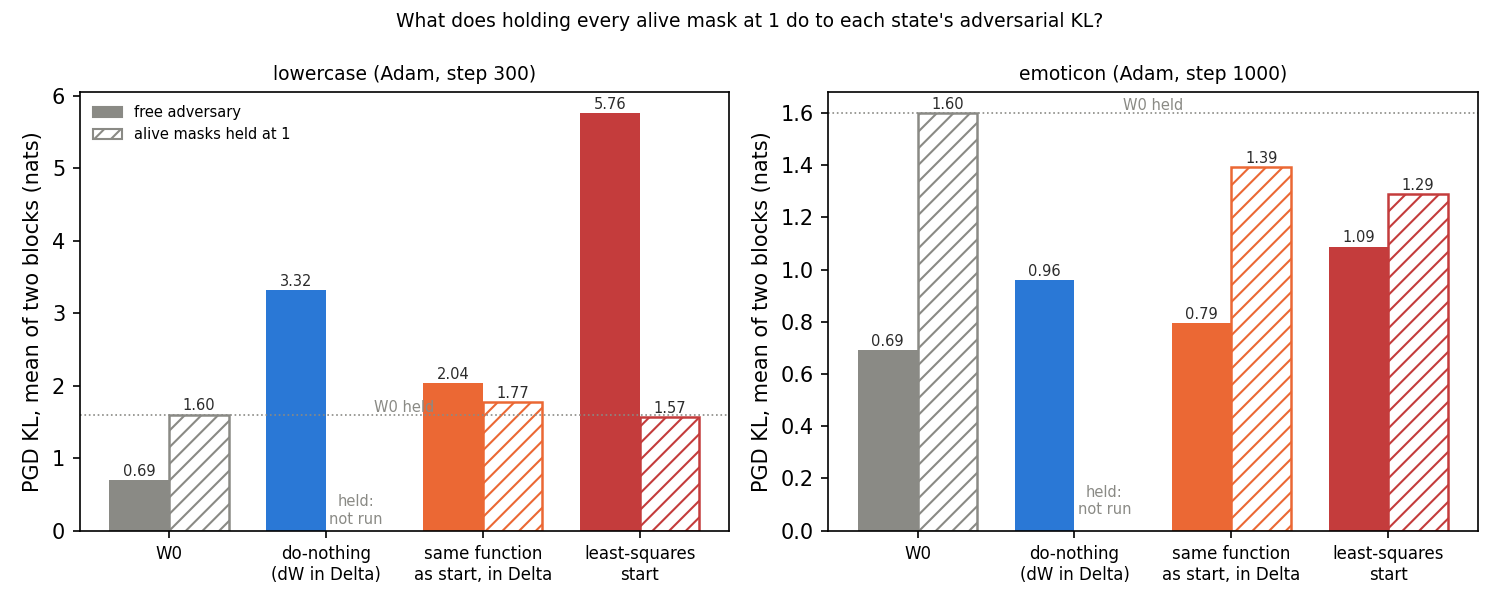

In [ ]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/hold.png", width=1000)

**Reading it.** It does, but the hold removes most of everything, so this is not yet specific to the placement. Under the hold the lowercase start reads 1.57 nats and the same function in Δ 1.77, so the placement part is gone; the filed share removed is 1.02 against a bar of 0.75.

Two things qualify this. First, the hold changes the adversary a lot: W₀ reads 1.60 nats held against 0.69 free, above the expected 0.5 to 1.2. A mask at 1 is a setting the free adversary may choose, so the 20-step free search is not finding the strongest masks at W₀. Held ratios therefore divide by a different, larger number; computed in nats, the share removed is still 1.06 on lowercase. Second, the same function in Δ has no change on the alive subcomponents, yet the hold cuts its excess over W₀ from 1.35 nats to 0.17. If the hold flattens every state, it says nothing about the placement. Do-nothing under the hold, marked "not run" in the figure, is the read that decides.


## Do random masks see the placement part?


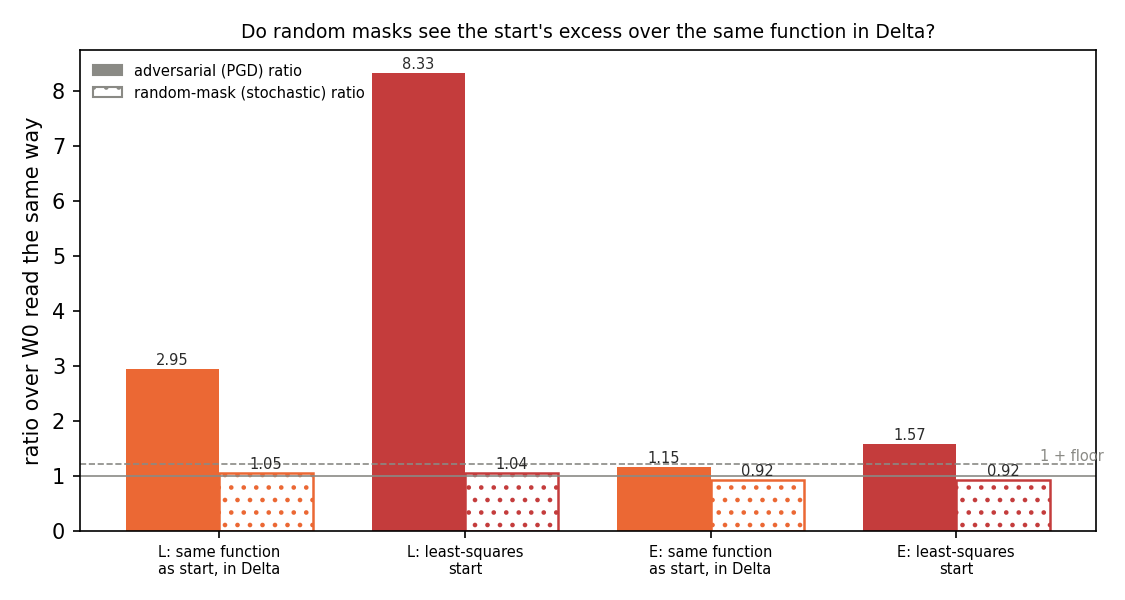

In [ ]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/random.png", width=1000)

**Reading it.** No: only the adversary sees it. Under random masks the start and the same function in Δ read within 1% of each other on both tasks, while the adversary puts them 5.39 ratio points apart on lowercase. All four random-mask ratios sit near 1, inside the expected 0.9 to 1.2. The random read's own noise was not measured.


## Do the per-subcomponent changes cancel on the failing states only?


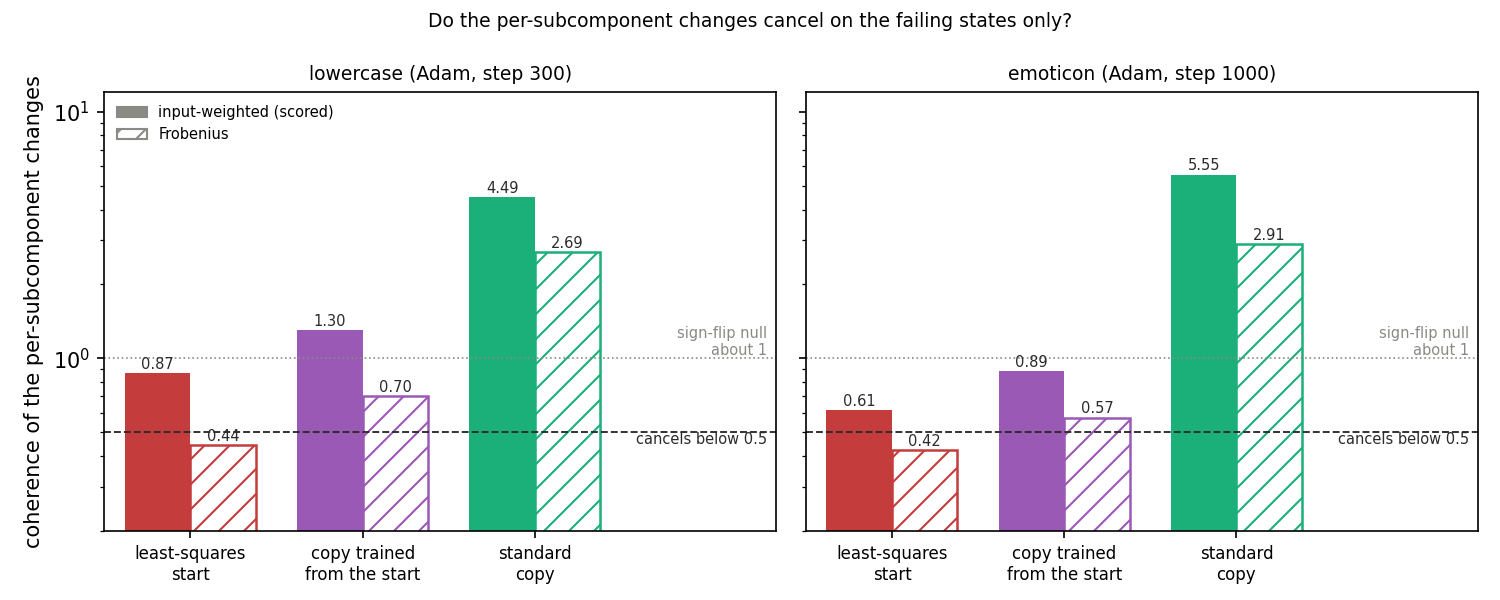

In [ ]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/coherence.png", width=1000)

**Reading it.** No. Input-weighted, the start reads 0.87 on lowercase and 0.61 on emoticon, above the cancelling bar of 0.5, and the copy trained from the start, which keeps the excess, reads 1.30 and 0.89. The standard copy's changes add up strongly, at 4.49 and 5.55. Frobenius coherence puts the start below 0.5, matching E17's 0.44, but the copy from the start still does not cancel. Cancellation separates the start from the standard copy, not the failing states from the faithful one.


## What we learned

The least-squares start's poor faithfulness on these fine-tunes comes from placing the change on the alive subcomponents, not from dropping the split's remainder: the dropped part, if anything, helps. In Δ a change shares one adversarial knob per matrix; on the subcomponents it rides thousands of separate masks, and the adversary uses them. For `GOALS.md`, this means a split that keeps the weights close to the fine-tune can still make the decomposition less faithful than leaving the update outside it. Whether the alive masks alone carry this stays open until do-nothing is read under the hold.

## How compelling is the evidence

Lowercase's placement part is about nine times its bar; emoticon's is under two, from one adversary seed. One row set, one fine-tune per task, one L40. The hold is a different adversary from the free one and was read on only two states per task besides W₀. Coherence is weight-side only.

## Surprises

- The function part is negative on both tasks: the same function in Δ reads 2.95 on lowercase, where 4 to 6 was expected.
- W₀ held reads 1.60 nats, above the expected 0.5 to 1.2: the free adversary at W₀ finds less than a setting it is allowed.
- Emoticon read "placement", where "within the floor" was expected, because the rule tests each part, not the whole excess.

## What next

- **Do-nothing and a standard teacher-trained copy under the hold**, being coded as E127 Amendment 1. If do-nothing keeps its excess there, the alive masks carry the placement part; if it reads like W₀ held, the hold has no teeth and the exposure reading is unreadable.
- **A stronger free adversary at W₀**, more steps or restarts. If it reaches 1.60, every free ratio has been read against a weak denominator.


## Scorecard

| rule | read | lean | verdict |
|---|---|---|---|
| A lowercase: function or placement | function −1.85, placement 5.39 | placement 0.5 | placement |
| A emoticon | function −0.24, placement 0.42 | within the floor 0.6 | placement; lean missed |
| B lowercase: hold removes it, H ≥ 0.75 | H 1.02 | alive masks 0.5 | the alive masks; not yet specific |
| B emoticon, reported only | H 1.15 | none | the alive masks |
| C both: random masks, q ≥ 0.209 | q −0.009, 0.005 | adversary only 0.8 | adversary only |
| D both: start and copy from it κ < 0.5, standard not | 0.87, 1.30; 0.61, 0.89 | 0.5 / 0.5 | does not track |

| expected | read | verdict |
|---|---|---|
| controls reproduce E121 and E122 | exact | held |
| W₀ held 0.5-1.2 nats | 1.60 | missed |
| same function in Δ, lowercase, 4-6 | 2.95 | missed |
| random-mask ratios 0.9-1.2 | 0.92-1.05 | held |
| start κ 0.3-0.6 | 0.87, 0.61 | missed |
| standard copy κ 2-4 | 4.49, 5.55 | missed |

The full list is in the report.

## Not run

- Do-nothing under the hold, on either task: E127 Amendment 1.
- Any standard teacher-trained copy under the hold, and the copy from the start under the hold: E127 Amendment 1.
- Adversary seeds 1 and 2; a stronger free adversary; a hold at the CI values or on a subset of subcomponents; Pile set B; the random read's noise floor.

**Provenance.** `experiments/ls_start_faith/results/ls_start_faith.json`; report `reports/analyses/2026-11-06_analysis_e127-ls-start-faithfulness.md`; MATS debug L40 jobs 54836 and 54874, about 31 min, $0.
